# 02 · Manifold — principal-curve trajectory (whole malignant manifold)

Li 2017's malignant manifold is **non-branching**: the gastrulation / somitogenesis /
neural-crest developmental signatures form a single monotone gradient (Gast & pSom co-vary;
Crest is the opposite, terminal end) rather than a hub radiating into discrete arms. The correct
topology is therefore a **principal curve** (ElPiGraph, non-branching by construction) fit on the
**joint Harmony embedding** — *not* a re-embedding (re-embedding an elongated compartment
fabricates folds; the evaluation-run failure mode).

**Scope decision (derived, not inherited).** The manifold is not split into a low-cycling and a
cycling lobe here: cell-cycle phase is scored de-novo (01) and — as shown below — is **orthogonal**
to the developmental axis (pseudotime↔cycling ρ≈0), so there is no proliferation lobe to exclude.
The whole malignant manifold is the honest developmental object. The curve is rooted at the
gastrulation/somitogenesis-high tip and pseudotime flows to the neural-crest terminus.
Deliverable: `manifold.h5ad`, `manifold.pdf`.

In [ ]:
import os, sys, glob, io, contextlib
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [ ]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
pth_feat = os.path.join(pth_data, 'features', 'biomart')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load processed manifold and score developmental modules
All cells keep their *joint embedding coordinates* — no re-embedding. The three embryonic
signatures (Gastrulation / Somitogenesis / Neural-crest) are scored against the shared **union**
control pool on the full gene matrix, then graph-smoothed over the kNN graph to read geography
rather than SmartSeq2 per-cell dropout.

In [ ]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('whole malignant manifold:', adata.shape[0], 'cells on the joint embedding')
xy = adata.obsm['X_umap']; c = xy - xy.mean(0); _,s,_ = np.linalg.svd(c, full_matrices=False)
print(f'UMAP aspect ratio (major/minor std): {s[0]/s[1]:.2f}')

feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
label = {'GSE162534':'Gast','GSE229103':'pSom','rRNAModifications':'Crest'}
for src,lab in label.items():
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False,
                      gene_pool=g_ref, random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present | mean {adata.obs[lab].mean():+.4f}')
# graph-smooth for geography
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,lab in enumerate(['Gast','pSom','Crest']): adata.obs[lab+'_sm'] = S[:,j]

whole malignant manifold: 248 cells on the joint embedding
UMAP aspect ratio (major/minor std): 3.24
Gast: 67/81 genes present | mean -0.0964
pSom: 76/98 genes present | mean +0.1120
Crest: 92/104 genes present | mean +0.0084


### Scope decision — cycling is orthogonal to the developmental axis
Two facts decide the scope: (i) the smoothed developmental signatures co-vary as **one axis**
(Gast↔pSom positive, both opposite Crest); (ii) the developmental gradient is **not** aligned to
proliferation — the cell-cycle covariate barely tracks the axis. So there is no cycling lobe to
excise; the whole manifold is carried into the trajectory (Bischoff/Sun no-scoping precedent).

In [ ]:
print('smoothed spatial correlations on the whole manifold:')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    r = np.corrcoef(adata.obs[a], adata.obs[b])[0,1]; print(f'  {a} vs {b}: r = {r:+.2f}')
adata.obs['cyc_score'] = adata.obs[['S_score','G2M_score']].max(1)
print('\nper-phase developmental means:')
print(adata.obs.groupby('cell_cycle_phase', observed=True)[['Gast_sm','pSom_sm','Crest_sm']].mean().round(3).to_string())
print('-> developmental axis co-varies as one gradient; scope = whole manifold (no lobe excision).')
sub = adata

smoothed spatial correlations on the whole manifold:
  Gast_sm vs pSom_sm: r = +0.89
  Crest_sm vs Gast_sm: r = -0.96
  Crest_sm vs pSom_sm: r = -0.97

per-phase developmental means:
                  Gast_sm  pSom_sm  Crest_sm
cell_cycle_phase                            
G1                 -0.092    0.112     0.011
G2M                -0.101    0.102     0.023
S                  -0.115    0.084     0.051
-> developmental axis co-varies as one gradient; scope = whole manifold (no lobe excision).


### Fit the principal curve (ElPiGraph) + fold-freeness check
`Nodes/epg_lambda/epg_mu` give a **fold-free** monotone backbone. A node self-approach ratio > 1
(minimum distance between graph-non-adjacent nodes, in units of median edge length) certifies the
curve does not fold back on itself. `epg_mu=100` is strong bending regularisation (smooth arc, not
a sharp V). We assert **0 forks** (non-branching) and a self-approach > 1 (no fold).

In [ ]:
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii,jj = np.where(np.triu(B>0)); med_edge = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a,b] >= 3: dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    tips = int(((B>0).sum(0)==1).sum()); forks = int(((B>0).sum(0)>=3).sum())
    return dmin/med_edge, tips, forks

with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(sub, Nodes=15, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa, tips, forks = fold_diag(sub)
print(f'curve: {tips} tips, {forks} forks | fold self-approach ratio = {sa:.2f} (>1 = fold-free)')
assert forks == 0 and sa > 1, 'topology check failed'

curve: 2 tips, 0 forks | fold self-approach ratio = 3.00 (>1 = fold-free)


### Derive the root (data-driven, developmental order)
Gast/pSom is the **early** developmental program, Crest is **late**. The root is therefore the
curve tip where Gast+pSom is highest and Crest lowest — never the Crest tip or a proliferation
state. Pseudotime then flows from that origin to the neural-crest terminus.

In [ ]:
B = np.asarray(sub.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(sub.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for tp in tps:
    m = np.isin(hard, np.where(D[tp]<=3)[0])
    info[tp] = (sub.obs['Gast_sm'][m].mean(), sub.obs['pSom_sm'][m].mean(),
                sub.obs['Crest_sm'][m].mean(), sub.obs['cyc_score'][m].mean())
    print(f'tip {tp}: Gast={info[tp][0]:+.4f} pSom={info[tp][1]:+.4f} Crest={info[tp][2]:+.4f} cyc={info[tp][3]:+.3f}')
root = int(max(tps, key=lambda tp: info[tp][0]+info[tp][1]-info[tp][2]))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(sub, root); scf.tl.pseudotime(sub, n_map=1, seed=SEED)
t = sub.obs['t'].values
print('gradient along pseudotime (Spearman rho):')
for s in ['Gast_sm','pSom_sm','Crest_sm','cyc_score']:
    rho,p = spearmanr(t, sub.obs[s]); print(f'  {s}: rho={rho:+.3f} p={p:.1e}')

tip 0: Gast=-0.0748 pSom=+0.1158 Crest=-0.0070 cyc=+0.056
tip 2: Gast=-0.1339 pSom=+0.0772 Crest=+0.0708 cyc=+0.352
derived root = tip 0 (Gast/pSom-high, Crest-low)
gradient along pseudotime (Spearman rho):
  Gast_sm: rho=-0.817 p=1.1e-60
  pSom_sm: rho=-0.369 p=2.0e-09
  Crest_sm: rho=+0.563 p=3.5e-22
  cyc_score: rho=-0.010 p=8.7e-01


### Reorient to house style (pseudotime left → right)
Orient using only raw UMAP coordinates (discrete sign choice, no rotation). This trajectory is
already **horizontal** in the raw embedding, so the house transform is the **identity**
(`X_umap_lin` = raw UMAP); the assertion confirms low pseudotime lands on the left.

In [ ]:
xy = sub.obsm['X_umap'].copy(); t = sub.obs['t'].values
xyr = np.column_stack([xy[:,0], xy[:,1]])
r = float(np.corrcoef(xyr[:,0], t)[0,1])
if r < 0:
    xyr[:,0] = -xyr[:,0]; r = -r
assert r > 0, f'pseudotime not left->right (corr={r:+.2f})'
sub.obsm['X_umap_lin'] = xyr
print(f'orientation: identity (already horizontal); corr(x_lin, pseudotime) = {r:+.2f}')

orientation: identity (already horizontal); corr(x_lin, pseudotime) = +0.94


### Save manifold + trajectory figure (deliverable `manifold.pdf`)

saved manifold.h5ad + manifold.pdf


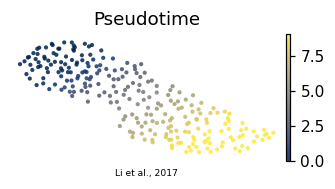

In [ ]:
sub.uns['epg'] = {'NodePositions': np.asarray(sub.uns['epg']['NodePositions'])}
sub.write(os.path.join(pth_out, 'manifold.h5ad'))
xl = sub.obsm['X_umap_lin']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
plot = sub.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=30, alpha=.85, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.text(.5,-.12,'Li et al., 2017', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight')
print('saved manifold.h5ad + manifold.pdf')